In [1]:
from pathlib import Path
import sys
import importlib
import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
import src.modeling as modeling
importlib.reload(modeling)
from src.modeling import MODEL_LABELS, calculate_metrics

MODELS_DIR = PROJECT_ROOT / 'models'
models = {
    'logistic': joblib.load(MODELS_DIR / 'modelo_logistico.joblib'),
    'neural': joblib.load(MODELS_DIR / 'modelo_neuronal.joblib'),
}
evaluation = joblib.load(MODELS_DIR / 'evaluation_data.joblib')
X_test, y_test = evaluation['x_test'], evaluation['y_test']
print(f'Casos evaluados: {len(y_test)}')

Casos evaluados: 61


In [2]:
results = {}
for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    results[name] = calculate_metrics(y_test, predictions, probabilities)

metrics_table = pd.DataFrame(results).T[[
    'accuracy', 'precision', 'recall', 'specificity', 'f1', 'roc_auc'
]]
metrics_table.index = [MODEL_LABELS[name] for name in metrics_table.index]
metrics_table.style.format('{:.2%}')

,accuracy,precision,recall,specificity,f1,roc_auc
Regresión Logística,81.97%,54.55%,92.31%,79.17%,68.57%,97.28%
Red Neuronal Artificial,77.05%,40.00%,15.38%,93.75%,22.22%,80.77%


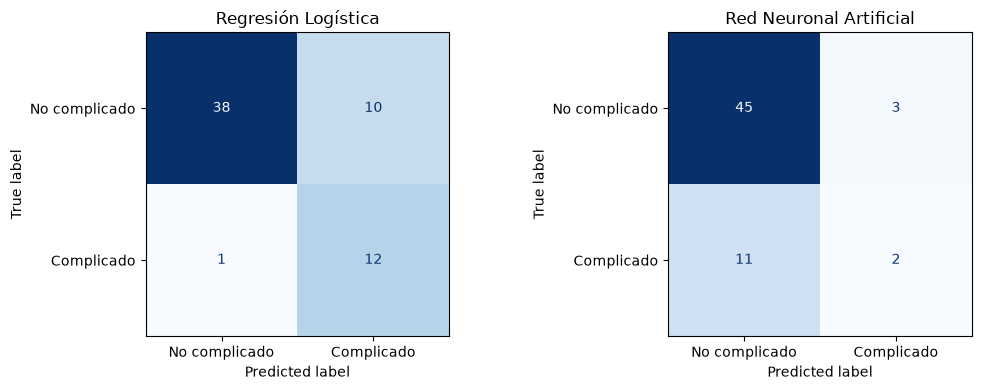

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test,
        display_labels=['No complicado', 'Complicado'],
        cmap='Blues', ax=ax, colorbar=False
    )
    ax.set_title(MODEL_LABELS[name])
plt.tight_layout()
plt.show()

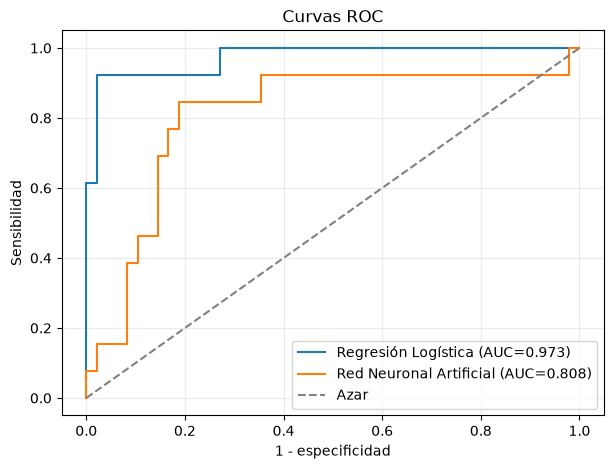

In [4]:
plt.figure(figsize=(7, 5))
for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    score = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{MODEL_LABELS[name]} (AUC={score:.3f})')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Azar')
plt.xlabel('1 - especificidad')
plt.ylabel('Sensibilidad')
plt.title('Curvas ROC')
plt.legend()
plt.grid(alpha=.25)
plt.show()